# Kinematic slip on a Slab2 slab, meshed by gmsh, step 1: the mesh and the synthetic data

The [kinematic_mesh](../kinematic_mesh) example meshes an idealized slab the simplest way: a grid of 8 x 8 cells, each cut into two triangles. Real fault meshes are made differently. The geometry of a subduction interface comes from a model such as [Slab2](https://doi.org/10.1126/science.aat4723) (Hayes et al., 2018), and a mesher such as [gmsh](https://gmsh.info) triangulates it with nearly equilateral triangles whose size grows with the depth, as the resolution of the data drops.

This example does both, under Ecuador, where kinematic_mesh's Pedernales-like rupture sits: a patch of Slab2's South America interface, 160 km along strike and 160 km down dip from its 8 km depth contour, meshed by gmsh into 132 triangles graded from 17 km at the top to 34 km at the base. It repeats kinematic_mesh's synthetic on it: stations on land, the true rupture, the noise. This notebook makes the mesh and the data; [step 2](step2_altar.ipynb) runs the Bayesian inversion with AlTar, with the slips sampled as a magnitude and a rake.

It needs CSI (with `TriangularPatchesKin`), gmsh (`pip install gmsh`), pyrocko and its store `crust2_2hz_d0`, AlTar 2, and, for one check, fim-python. The first cell downloads the Slab2 distribution, 140 MB, once.

In [1]:
import os
import io
import time
import tarfile
import urllib.request
import warnings
# csi's docstrings hold escape sequences python warns about, unrelated to this example
warnings.filterwarnings('ignore', category=SyntaxWarning)
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
import gmsh
import csi

# the directory of the pyrocko stores
store_dir = os.environ.get('PYROCKO_STORES', os.path.expanduser('~/gfstores'))

# Slab2's depth grid of South America, from the USGS distribution (ScienceBase item 5aa1b00ee4b0b1c392e86467)
grid = 'slab2/sam_slab2_dep_02.23.18.grd'
url = ('https://www.sciencebase.gov/catalog/file/get/5aa1b00ee4b0b1c392e86467'
       '?f=__disk__d5%2F91%2F39%2Fd591399bf4f249ab49ffec8a366e5070fe96e0ba')
if not os.path.exists(grid):
    os.makedirs('slab2', exist_ok=True)
    with urllib.request.urlopen(url) as stream, tarfile.open(fileobj=stream, mode='r|gz') as tar:
        for member in tar:
            if member.name.endswith('/' + os.path.basename(grid)):
                with open(grid, 'wb') as out:
                    out.write(tar.extractfile(member).read())
                break
print(f"{grid}: {os.path.getsize(grid) / 1e3:.0f} kB")

slab2/sam_slab2_dep_02.23.18.grd: 581 kB


## Slab2

The grid is a netCDF file: depths in km, negative down, every 0.05° of longitude (east, 0 to 360) and latitude, NaN where there is no slab.

In [2]:
with h5py.File(grid) as h5:
    lon_grid = np.asarray(h5['x'], dtype=float)
    lat_grid = np.asarray(h5['y'], dtype=float)
    depth_grid = -np.asarray(h5['z'], dtype=float)
lon_grid = np.where(lon_grid > 180, lon_grid - 360, lon_grid)
slab_depth = RegularGridInterpolator((lat_grid, lon_grid), depth_grid, bounds_error=False, fill_value=np.nan)
print(f"{lon_grid.size} x {lat_grid.size} nodes, longitudes {lon_grid.min():.1f} to {lon_grid.max():.1f}, "
      f"latitudes {lat_grid.min():.1f} to {lat_grid.max():.1f}, depths to {np.nanmax(depth_grid):.0f} km")

581 x 1281 nodes, longitudes -86.0 to -57.0, latitudes -49.0 to 15.0, depths to 674 km


## Surface coordinates

AlTar's kinematic model needs, besides the triangles, coordinates on the fault surface: the rupture front starts at a hypocenter given in them, and gmsh meshes in them. An idealized slab whose cross-sections are all the same unrolls onto a plane, and its surface coordinates are exact. Slab2's interface is curved along strike too, and doesn't; here they are made from cross-sections:

- u, the distance along a reference strike, N21°E, the trend of the trench off Ecuador, from a point at the trench at 0.75°S;
- v, the distance down dip along the cross-section of Slab2 at u, perpendicular to that strike, from where the slab is 8 km deep.

A point (u, v) goes onto the slab through the cross-sections either side of u. Down dip, distances are exact; along strike, where the cross-sections change, lengths on the slab differ a little from those in (u, v): the check below measures it on the edges of the mesh.

In [3]:
ORIGIN, STRIKE = (-81.29, -0.75), 21.0
LENGTH, WIDTH, TOP = 160.0, 160.0, 8.0

class Slab:
    # the slab's depth, and the map from the surface coordinates onto it, in the local frame of {fault}

    def __init__(self, fault, step=1.0):
        self.fault = fault
        self.x0, self.y0 = fault.ll2xy(*ORIGIN)
        phi = np.radians(STRIKE)
        self.es = np.array([np.sin(phi), np.cos(phi)])
        self.eh = np.array([np.cos(phi), -np.sin(phi)])
        # the cross-sections, every {step} km along strike, sampled every 0.25 km across it
        self.u = np.arange(0.0, LENGTH + step / 2, step)
        h = np.arange(-60.0, 260.0, 0.25)
        self.profiles = []
        for u in self.u:
            zz = self.depth(self.x0 + u * self.es[0] + h * self.eh[0], self.y0 + u * self.es[1] + h * self.eh[1])
            ok = np.isfinite(zz)
            hh, zz = h[ok], zz[ok]
            # from where the slab is TOP deep, the distance down dip along the cross-section
            start = np.flatnonzero(zz >= TOP)[0]
            h0 = np.interp(TOP, zz[start - 1:start + 1], hh[start - 1:start + 1])
            hh, zz = np.concatenate([[h0], hh[start:]]), np.concatenate([[TOP], zz[start:]])
            v = np.concatenate([[0.0], np.cumsum(np.hypot(np.diff(hh), np.diff(zz)))])
            self.profiles.append((v, hh, zz))

    def depth(self, x, y):
        lon, lat = self.fault.xy2ll(np.asarray(x), np.asarray(y))
        return slab_depth(np.column_stack([np.ravel(lat), np.ravel(lon)])).reshape(np.shape(x))

    def xyz(self, uv):
        # the points (x, y, depth) of the surface coordinates {uv}, linear between the cross-sections
        uv = np.atleast_2d(uv)
        k = np.clip(np.searchsorted(self.u, uv[:, 0]) - 1, 0, len(self.u) - 2)
        t = (uv[:, 0] - self.u[k]) / (self.u[k + 1] - self.u[k])
        out = np.zeros((len(uv), 3))
        for side, weight in [(0, 1 - t), (1, t)]:
            for i in range(len(uv)):
                v, hh, zz = self.profiles[k[i] + side]
                h, z = np.interp(uv[i, 1], v, hh), np.interp(uv[i, 1], v, zz)
                out[i] += weight[i] * np.array([self.x0 + self.u[k[i] + side] * self.es[0] + h * self.eh[0],
                                                self.y0 + self.u[k[i] + side] * self.es[1] + h * self.eh[1], z])
        # back onto the slab: Slab2's depth at the interpolated position
        out[:, 2] = self.depth(out[:, 0], out[:, 1])
        return out

fault = csi.TriangularPatchesKin("ecuador", lon0=-80.0, lat0=0.0, verbose=False)
slab = Slab(fault)
print(f"{len(slab.u)} cross-sections; the slab {slab.xyz([[0, WIDTH]])[0, 2]:.1f} to {slab.xyz([[LENGTH, WIDTH]])[0, 2]:.1f} km deep "
      f"at the base, {WIDTH:.0f} km down dip")

161 cross-sections; the slab 65.1 to 65.9 km deep at the base, 160 km down dip


## The mesh

gmsh triangulates the rectangle of the surface coordinates by its frontal-Delaunay algorithm, with a size from a callback alone: 17 km where the slab is 8 km deep to 34 km at the base, linear in the depth. The vertices then go onto the slab. For comparison, and for the placement of the stations below, the regular mesh of kinematic_mesh: 8 x 8 cells of 20 km, two triangles each.

In [4]:
shallow, deep = 17.0, 34.0
zmax = max(slab.xyz([[u, WIDTH]])[0, 2] for u in np.linspace(0, LENGTH, 9))
size = lambda u, v: shallow + (deep - shallow) * (slab.xyz([[u, v]])[0, 2] - TOP) / (zmax - TOP)

gmsh.initialize()
gmsh.option.setNumber('General.Terminal', 0)
gmsh.model.add('slab2')
gmsh.model.occ.addRectangle(0, 0, 0, LENGTH, WIDTH)
gmsh.model.occ.synchronize()
for option in ['MeshSizeExtendFromBoundary', 'MeshSizeFromPoints', 'MeshSizeFromCurvature']:
    gmsh.option.setNumber(f'Mesh.{option}', 0)
gmsh.option.setNumber('Mesh.Algorithm', 6)
gmsh.model.mesh.setSizeCallback(lambda dim, tag, x, y, z, lc: float(size(x, y)))
gmsh.model.mesh.generate(2)
tags, coords, _ = gmsh.model.mesh.getNodes()
uv = coords.reshape(-1, 3)[:, :2]
index = {t: i for i, t in enumerate(tags)}
_, _, nodes = gmsh.model.mesh.getElements(2)
faces = np.array([index[t] for t in nodes[0]]).reshape(-1, 3)
gmsh.finalize()
# counterclockwise in the surface coordinates
a, b, c = uv[faces[:, 0]], uv[faces[:, 1]], uv[faces[:, 2]]
flip = (b - a)[:, 0] * (c - a)[:, 1] - (b - a)[:, 1] * (c - a)[:, 0] < 0
faces[flip] = faces[flip][:, [0, 2, 1]]
fault.setMesh(slab.xyz(uv), faces)
fault.uv = uv

# kinematic_mesh's regular mesh, on the same slab
ru, rv = np.meshgrid(np.linspace(0, LENGTH, 9), np.linspace(0, WIDTH, 9), indexing='ij')
regular_uv = np.column_stack([ru.ravel(), rv.ravel()])
cell = lambda i, j: i * 9 + j
regular_faces = []
for i in range(8):
    for j in range(8):
        p, q, r, s = cell(i, j), cell(i + 1, j), cell(i + 1, j + 1), cell(i, j + 1)
        regular_faces += [(p, q, r), (p, r, s)] if (i + j) % 2 else [(p, q, s), (q, r, s)]
regular = csi.TriangularPatchesKin("regular", lon0=-80.0, lat0=0.0, verbose=False)
regular.setMesh(slab.xyz(regular_uv), np.array(regular_faces))
regular.uv = regular_uv

def shapes(f):
    p = f.Vertices[f.Faces]
    edges = np.linalg.norm(p[:, [1, 2, 0]] - p, axis=2)
    angle = lambda k: np.degrees(np.arccos(((p[:, (k + 1) % 3] - p[:, k]) * (p[:, (k + 2) % 3] - p[:, k])).sum(1)
                                           / edges[:, k] / edges[:, (k + 2) % 3]))
    smallest = np.min([angle(k) for k in range(3)], axis=0)
    surface = np.linalg.norm(f.uv[f.Faces[:, [1, 2, 0]]] - f.uv[f.Faces], axis=2)
    return (f"{len(f.Faces)} triangles, {len(f.Vertices)} vertices, {f.Vertices[:, 2].min():.1f} to {f.Vertices[:, 2].max():.1f} km deep; "
            f"edges {edges.min():.1f} to {edges.max():.1f} km; smallest angle {smallest.min():.0f} degrees, median {np.median(smallest):.0f}; "
            f"edge lengths on the slab against the surface coordinates {100 * np.abs(edges / surface - 1).max():.1f}% off at most")

print('gmsh:   ', shapes(fault))
print('regular:', shapes(regular))

gmsh:    132 triangles, 82 vertices, 8.0 to 67.4 km deep; edges 12.1 to 34.2 km; smallest angle 42 degrees, median 54; edge lengths on the slab against the surface coordinates 5.5% off at most
regular: 128 triangles, 81 vertices, 8.0 to 67.5 km deep; edges 20.0 to 29.9 km; smallest angle 42 degrees, median 45; edge lengths on the slab against the surface coordinates 5.6% off at most


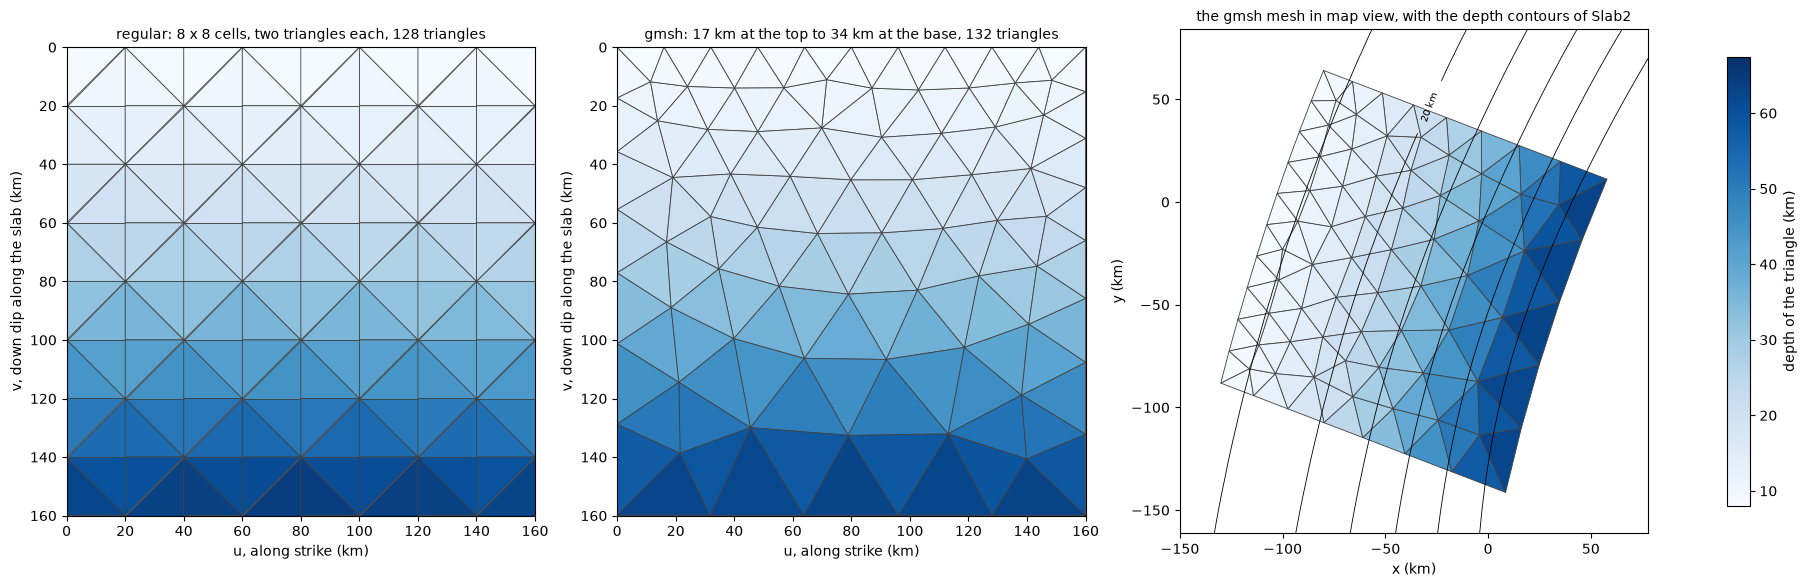

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), layout='constrained')
depths = np.concatenate([fault.Vertices[:, 2], regular.Vertices[:, 2]])
norm = plt.Normalize(depths.min(), depths.max())
for ax, (f, title) in zip(axes[:2], [(regular, 'regular: 8 x 8 cells, two triangles each'),
                                     (fault, f'gmsh: {shallow:.0f} km at the top to {deep:.0f} km at the base')]):
    depth = f.Vertices[f.Faces][:, :, 2].mean(1)
    pc = ax.tripcolor(f.uv[:, 0], f.uv[:, 1], f.Faces, facecolors=depth, cmap='Blues', norm=norm, edgecolors='0.25', lw=0.6)
    ax.set_aspect('equal'); ax.set_xlim(0, LENGTH); ax.set_ylim(WIDTH, 0)
    ax.set_xlabel('u, along strike (km)'); ax.set_ylabel('v, down dip along the slab (km)')
    ax.set_title(f'{title}, {len(f.Faces)} triangles', fontsize=10)
ax = axes[2]
V, F = fault.Vertices, fault.Faces
ax.tripcolor(V[:, 0], V[:, 1], F, facecolors=V[F][:, :, 2].mean(1), cmap='Blues', norm=norm, edgecolors='0.25', lw=0.6)
lon, lat = np.meshgrid(np.linspace(-82, -78.5, 141), np.linspace(-1.5, 1.5, 121))
x, y = fault.ll2xy(lon.ravel(), lat.ravel())
z = slab.depth(x, y)
ok = np.isfinite(z)
cs = ax.tricontour(x[ok], y[ok], z[ok], levels=[10, 20, 30, 40, 50, 60], colors='k', linewidths=0.6)
ax.clabel(cs, fmt='%d km', fontsize=7)
ax.set_aspect('equal'); ax.set_xlim(V[:, 0].min() - 20, V[:, 0].max() + 20); ax.set_ylim(V[:, 1].min() - 20, V[:, 1].max() + 20)
ax.set_xlabel('x (km)'); ax.set_ylabel('y (km)'); ax.set_title('the gmsh mesh in map view, with the depth contours of Slab2', fontsize=10)
fig.colorbar(pc, ax=axes, shrink=0.7, label='depth of the triangle (km)')
plt.show()

## Rakes, source points and stations

As in kinematic_mesh: the slip of each patch has a component along the convergence of the Nazca plate, N83°E, and one across it, and each patch carries source points, 3 along each edge. The stations are placed as kinematic_mesh places them, in the frame of the trench, on land at least 1 km from the source points of the regular mesh: 18 waveform stations, 30 GPS and 107 line-of-sight points. They are the same for both meshes, which keeps a comparison of the meshes on the same data possible.

In [6]:
parallel = fault.convergenceRakes(83.0)
rakes = (parallel + 90.0, parallel)
fault.setSourcePoints(3)
regular.setSourcePoints(3)
Np = len(fault.patch)
print(f"{Np} patches, {len(fault.sources_xyz)} source points; rake along the convergence {parallel.min():.1f} to {parallel.max():.1f} degrees")

rng = np.random.default_rng(2016)
coast = 45.0
x0, y0 = fault.ll2xy(*ORIGIN)
phi = np.radians(STRIKE)
sources = regular.sources_xyz[:, :2]
point = lambda a, c: (x0 + a * np.sin(phi) + c * np.cos(phi), y0 + a * np.cos(phi) - c * np.sin(phi))

def land(count, near, far, spread=20.0):
    # {count} places on land, {near} to {far} km east of the coast, at least 1 km from the regular mesh's sources
    places = []
    while len(places) < count:
        a, c = rng.uniform(-spread, LENGTH + spread), coast + rng.uniform(near, far)
        x, y = point(a, c)
        if np.hypot(sources[:, 0] - x, sources[:, 1] - y).min() >= 1.0:
            places.append((x, y))
    return np.array(places)

def stations(name, places, prefix):
    data = csi.seismic(name, lon0=-80.0, lat0=0.0)
    data.setStat([f"{prefix}{k:03d}" for k in range(len(places))], *fault.xy2ll(places[:, 0], places[:, 1]), loc_format="LL")
    return data

kinematic = stations("kinematic", land(18, 2.0, 120.0), "K")
gps = stations("gps", land(30, 2.0, 150.0), "G")
ga, gc = np.meshgrid(np.linspace(-10, 170, 12), coast + np.linspace(3, 100, 10), indexing="ij")
insar_xy = np.array([point(a, c) for a, c in zip(ga.ravel(), gc.ravel())])
insar_xy = insar_xy[[np.hypot(sources[:, 0] - x, sources[:, 1] - y).min() >= 1.0 for x, y in insar_xy]]
insar = stations("insar", insar_xy, "I")
print(f"{len(kinematic.sta_name)} waveform stations, {len(gps.sta_name)} gps, {len(insar.sta_name)} line of sight points")

132 patches, 1188 source points; rake along the convergence 107.4 to 126.3 degrees
18 waveform stations, 30 gps, 107 line of sight points


## The Green's functions

The same engine and settings as kinematic_mesh: seismograms of the pyrocko store `crust2_2hz_d0` for a unit slip of each patch along each rake, bandpassed at 0.015 to 0.08 Hz, and the static offsets from the same store.

In [7]:
engine = csi.pyrockoengine("crust2_2hz_d0", store_dir, delta=1.0)
fault.setMu(engine.material)
start = time.perf_counter()
fault.buildKinGFs(kinematic, engine, Dt=1.0, npts=160, rakes=rakes, points=True, bandpass=(0.015, 0.08))
fault.buildBigGD(kinematic, Nt=85, Dt=1.0)
Ggps = fault.buildStaticGFs(gps, engine, rakes=rakes, points=True)
Gins = fault.buildStaticGFs(insar, engine, rakes=rakes, points=True)
los = np.array([0.62, -0.11, 0.78])  # east, north, up: a descending track
Glos = np.einsum("c,scp->sp", los, Gins.reshape(len(insar.sta_name), 3, -1))
print(f"{time.perf_counter() - start:.0f} s; big G {fault.bigG.shape}, gps {Ggps.shape}, line of sight {Glos.shape}")

133 s; big G (8640, 22440), gps (90, 264), line of sight (107, 264)


## The true rupture

kinematic_mesh's true model, the same functions of the centroids of the patches in surface coordinates: a 3 m asperity next to the hypocenter in the north, a 6 m one 70 km south, slip across the convergence of up to 0.3 m, rise times of 4 to 10 s with the slip, and a rupture velocity for each block of 40 x 40 km, 1.98 to 3.01 km/s. On the graded mesh, the blocks hold 3 to 16 triangles: few at depth, where the triangles are large.

In [8]:
uvc = np.array([uv[f].mean(0) for f in F])
a = np.exp(-((uvc - [118.0, 60.0]) ** 2).sum(1) / (2 * 15.0 ** 2))
b = np.exp(-((uvc - [55.0, 75.0]) ** 2).sum(1) / (2 * 18.0 ** 2))
slip_parallel = 0.2 + 3.0 * a + 6.0 * b
slip_across = 0.3 * (a - b)
risetime = 4.0 + 6.0 * (slip_parallel - slip_parallel.min()) / (slip_parallel.max() - slip_parallel.min())
hypocenter = np.array([125.0, 55.0])
blocks = np.clip((uvc / 40.0).astype(int), 0, 3)
groups = blocks[:, 0] * 4 + blocks[:, 1]
centers = np.array([uvc[groups == g].mean(0) for g in range(16)])
velocity = 2.2 + 0.6 * centers[:, 0] / 160.0 + 0.3 * np.sin(centers[:, 1] / 30.0)
print(f"velocity groups of {np.bincount(groups).min()} to {np.bincount(groups).max()} patches; velocities {velocity.min():.2f} to {velocity.max():.2f} km/s")

# AlTar's inputs: the mesh, the hypocenter and the velocity groups, the big G, and the true parameters
os.makedirs('input', exist_ok=True)
os.chdir('input')
fault.setHypoOnFault(*hypocenter)
fault.bigD = np.zeros(fault.bigG.shape[0])
fault.saveKinematic('mesh.h5')
with h5py.File('mesh.h5', 'a') as h5:
    h5['groups/velocity'] = groups
np.savetxt('truth.txt', np.concatenate([slip_across, slip_parallel, risetime, velocity, hypocenter])[None, :])
os.chdir('..')

velocity groups of 3 to 16 patches; velocities 1.98 to 3.01 km/s


The slip history of the true model comes from AlTar's kinematic model, run forward on the true parameters, as in kinematic_mesh:

In [9]:
!slipmodel.plexus forward --config=synthetic.pfg > input/synthetic.log 2>&1

In [10]:
Nt, dt = 85, 1.0
tk = np.arange(Nt) * dt
with h5py.File('input/truth.forward.h5') as h5:
    Mb = np.asarray(h5['Mb/mean_model']).reshape(Nt, 2, Np)
moment = (fault.mu * np.asarray(fault.area) * 1e6 * np.hypot(slip_across, slip_parallel)).sum()
print(f"Mw {2 / 3 * (np.log10(moment) - 9.1):.3f}")

Mw 7.946


## The rupture times

The rupture front comes from the eikonal equation on the fault, solved on a refinement of the mesh, each patch cut into 10 x 10 triangles, by the fast iterative method, in three dimensions: the surface coordinates only place the hypocenter. CSI's `castbigM` makes the same slip history from the slips, rise times and velocities of the patches, by AlTar's compiled model when AlTar is installed, or else by fim-python; both match AlTar's forward run here.

In [11]:
fault.slip[:, 0], fault.slip[:, 1] = slip_across, slip_parallel
fault.tr, fault.vr = risetime, velocity[groups]
for engine_name in ['altar', 'fim']:
    M = fault.castbigM(Nt, dt, engine=engine_name).reshape(Nt, 2, Np)
    print(f"castbigM by {engine_name}: against AlTar's forward run, {np.abs(M - Mb).max() / np.abs(Mb).max():.1e} of its largest value")

castbigM by altar: against AlTar's forward run, 0.0e+00 of its largest value


castbigM by fim: against AlTar's forward run, 2.4e-15 of its largest value


The solver is first order, and its fronts arrive a little late, by an amount that halves with the spacing of the refinement (the idealized slab of kinematic_mesh, where the exact times are known, shows it). Against a refinement 4 times finer:

In [12]:
times = {}
for refine in [10, 40]:
    fault.computeRuptureTimes(refine=refine, engine='altar')
    times[refine] = fault.sources_t0.copy()
late = times[10] - times[40]
print(f"at refine 10, against refine 40: {late.mean():.2f} s late on average, {late.max():.2f} s at most")

at refine 10, against refine 40: 0.14 s late on average, 0.30 s at most


A few tenths of a second, under 1% of the arrival times beyond 40 s. In this synthetic test it cancels, as the truth and the inversion share the solver; on real data, it would be absorbed by a slightly faster rupture velocity.

## The data

The waveforms, the GPS offsets and the line of sight of the true model, with kinematic_mesh's noise: 5 mm on the waveforms and the GPS, 1 cm on the line of sight.

waveforms: peak 39.4 cm; gps: peak 106.1 cm; line of sight: -53.0 to 40.5 cm


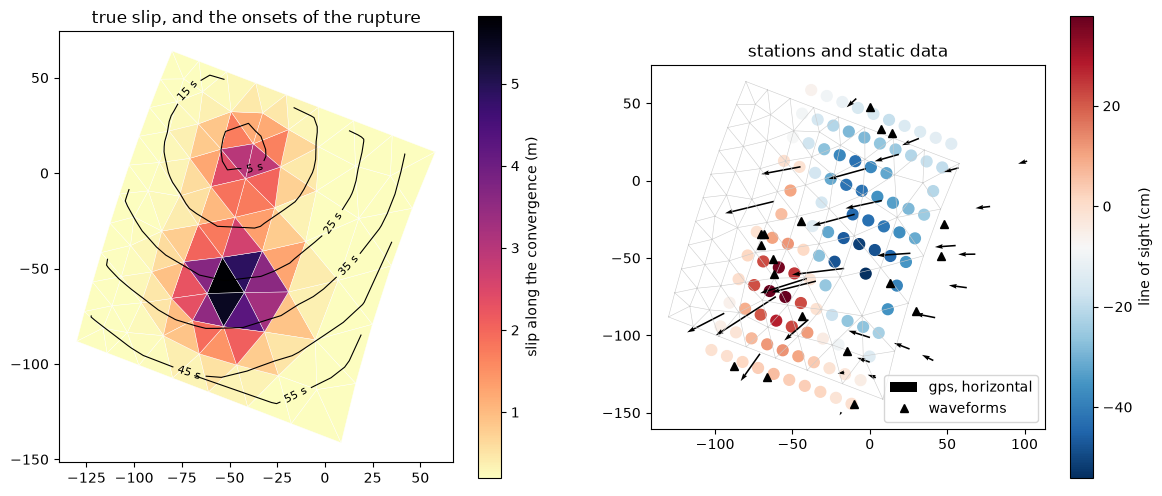

In [13]:
waveforms = fault.bigG @ Mb.ravel()
final = np.concatenate([slip_across, slip_parallel])
sigma = {'waveforms': 0.005, 'gps': 0.005, 'line of sight': 0.01}
d_waveforms = waveforms + sigma['waveforms'] * rng.standard_normal(waveforms.size)
d_gps = Ggps @ final + sigma['gps'] * rng.standard_normal(Ggps.shape[0])
d_los = Glos @ final + sigma['line of sight'] * rng.standard_normal(Glos.shape[0])
print(f"waveforms: peak {100 * np.abs(waveforms).max():.1f} cm; gps: peak {100 * np.abs(Ggps @ final).max():.1f} cm; "
      f"line of sight: {100 * (Glos @ final).min():.1f} to {100 * (Glos @ final).max():.1f} cm")

# the mean onset of each patch: the centroid time of its slip, less half its rise time
patch_onset = (tk[:, None] * Mb[:, 1]).sum(0) / Mb[:, 1].sum(0) - risetime / 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
pc = ax1.tripcolor(V[:, 0], V[:, 1], F, facecolors=slip_parallel, cmap='magma_r', edgecolors='w', lw=0.3)
fig.colorbar(pc, ax=ax1, label='slip along the convergence (m)')
centroids = V[F].mean(1)
cs = ax1.tricontour(centroids[:, 0], centroids[:, 1], patch_onset, levels=np.arange(5, 75, 10), colors='k', linewidths=0.8)
ax1.clabel(cs, fmt='%d s', fontsize=8)
ax1.set_aspect('equal'); ax1.set_title('true slip, and the onsets of the rupture')
gx, gy = fault.ll2xy(np.asarray(gps.lon), np.asarray(gps.lat))
ix, iy = fault.ll2xy(np.asarray(insar.lon), np.asarray(insar.lat))
kx, ky = fault.ll2xy(np.asarray(kinematic.lon), np.asarray(kinematic.lat))
sc = ax2.scatter(ix, iy, c=100 * d_los, cmap='RdBu_r', s=60)
fig.colorbar(sc, ax=ax2, label='line of sight (cm)')
o = d_gps.reshape(-1, 3)
ax2.quiver(gx, gy, o[:, 0], o[:, 1], scale=5, width=0.004, label='gps, horizontal')
ax2.plot(kx, ky, 'k^', label='waveforms')
ax2.triplot(V[:, 0], V[:, 1], F, color='0.8', lw=0.4)
ax2.set_aspect('equal'); ax2.set_title('stations and static data'); ax2.legend(loc='lower right')
plt.show()

## The files for AlTar

The same layout as kinematic_mesh's: the mesh and the big G from `saveKinematic`, the waveforms, the static Green's functions, data and covariance, and the truth, for step 2.

In [14]:
os.chdir('input')
with h5py.File('kinematicG.data.h5', 'w') as h5:
    h5['kinematicG.data'] = d_waveforms
d_static = np.concatenate([d_gps, d_los])
sigma_static = np.concatenate([np.full(d_gps.size, sigma['gps']), np.full(d_los.size, sigma['line of sight'])])
for name, values in [('static.gf', np.vstack([Ggps, Glos])), ('static.data', d_static), ('static.Cd', np.diag(sigma_static ** 2))]:
    with h5py.File(f'{name}.h5', 'w') as h5:
        h5[name] = values
with h5py.File('synthetic.h5', 'w') as h5:
    for name, values in [('across', slip_across), ('parallel', slip_parallel), ('risetime', risetime),
                         ('rupturevelocity', velocity), ('hypocenter', hypocenter)]:
        h5[f'true/{name}'] = values
    h5['true/Mb'] = Mb
    h5['mu'], h5['area'], h5['dt'] = fault.mu, np.asarray(fault.area), dt
    h5['stations'] = np.array(kinematic.sta_name, dtype='S')
for name in sorted(n for n in os.listdir('.') if n.endswith('.h5')):
    print(f"{name}: {os.path.getsize(name) / 1e6:.3g} MB")
os.chdir('..')

kinematicG.data.h5: 0.0712 MB
kinematicG.gf.h5: 1.55e+03 MB
mesh.h5: 0.0453 MB
static.Cd.h5: 0.313 MB
static.data.h5: 0.00362 MB
static.gf.h5: 0.418 MB
synthetic.h5: 0.192 MB
truth.forward.h5: 1.12 MB
